# **Question 4.9.1**
**1. What happens when we change how search engines work? What might users do? And what about advertisers?**

When search engine behavior changes, the following situations may occur:<br>
1. User Reactions: Users may react differently to changes in search engine behavior. Some users may adapt to and accept these changes, continuing to use the search engine for their queries. Other users may feel dissatisfied or confused because they are accustomed to specific search results and features. This may lead them to seek out alternative search engines or find other ways to obtain the information they need.<br>
2. Changes in User Behavior: If search engine behavior changes significantly, users may adjust their search strategies. They may change the keywords they use, try different search strategies, or use advanced search options to obtain more precise results. Some users may rely more heavily on other sources of information, such as social media, specialized websites, or apps.
3. Advertisers’ Response: Changes in search engine behavior may affect advertisers. Advertisers typically rely on search engines to provide exposure and traffic for their ad campaigns. If search engine behavior changes, advertisers may need to reassess their advertising strategies and delivery methods to ensure their ads continue to effectively reach their target audiences.
4. Ad Rankings and Competition: Changes in search engine behavior may affect ad rankings and competition. If a search engine adjusts its ad ranking algorithm or the way ads are displayed, advertisers may need to reassess their ad optimization strategies and budget allocations to adapt to these changes. Highly competitive industries may see shifts in ad bidding and adjustments to the competitive landscape.

# **Question 4.9.2**
**2.Implement a covariate offset detector. Hint: Build a classifier.**

In [1]:
import torch
import torchvision
from torch.nn import Module
from torchvision import datasets, models, transforms
import os
from torch.autograd import Variable
import torch.nn as nn
import torch.utils.data
import torch.nn.functional as F
from pathlib import Path
from d2l import torch as d2l
import gc
from PIL import Image
from collections import Counter
gc.collect()

# loading function
def get_mean_std(data_dir, name):
    data_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
    ])

    def find_bad_images(root_dir):
        transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
        ])
        bad = []
        for dirpath, _, files in os.walk(root_dir):
            for f in files:
                p = os.path.join(dirpath, f)
                size = os.path.getsize(p)
                if size == 0:
                    bad.append((p, "0字节", 0))
                    continue
                try:
                    img = Image.open(p)
                    mode = img.mode
                    t = transform(img)
                    for c in range(t.shape[0]):        # 逐通道
                        m = t[c].mean().item()
                        s = t[c].std().item()
                        if not torch.isfinite(t[c]).all():       # ← 更直接的判断
                            bad.append((p, f"channel {c} 非有限", size))
                            break
                        if not (0 <= m <= 1):
                            bad.append((p, f"channel {c} mean={m}", size))
                            break
                except Exception as e:
                    bad.append((p, f"读取失败: {e}", size))
        return bad

    bad = find_bad_images(os.path.join(data_dir, "train"))
    print(f"发现 {len(bad)} 张异常图：")
    for p, reason, size in bad[:50]:
        print(f"  {p}  |  {reason}  |  {size} bytes")


    image_datasets = datasets.ImageFolder(root=data_dir, transform=data_transforms)
    data_loader = torch.utils.data.DataLoader(image_datasets, batch_size=1, shuffle=False, num_workers=0)

    mean = torch.zeros(3)
    sq_mean = torch.zeros(3)
    n = 0
    shapes = Counter()
    for X, _ in data_loader:
        shapes[tuple(X.squeeze(0).shape)] += 1
        X = X.squeeze(0)
        mean += X.mean(dim=[1, 2])
        sq_mean += (X ** 2).mean(dim=[1, 2])
        n += 1

    print(shapes)
    mean /= n
    sq_mean /= n
    std = torch.sqrt(sq_mean - mean**2)

    print(name, ' mean: ', mean, ' std: ', std)
    return mean.tolist(), std.tolist()

def load_data_cartoon_vs_normal(data_dir, mean_list, std_list, batch_size=32):
    data_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean_list, std_list),
    ])
    # Path Concatenation
    image_datasets = datasets.ImageFolder(root=data_dir, transform=data_transforms)
    # Data Loader
    data_iter = torch.utils.data.DataLoader(image_datasets, batch_size=batch_size, shuffle=True)
    return (data_iter, image_datasets)

# Training Function
def train_epoch_ch4_9(net, train_iter, loss, updater, use_gpu=False, detector=None):
    train_acc = 0.0
    train_loss = 0.0
    total_samples = 0
    device = torch.device('cuda' if use_gpu else 'cpu')
    for batch, (X, y) in enumerate(train_iter, 1):
        X, y = X.to(device), y.to(device)
        y_hat = net(X)
        beta = None
        if detector is not None:
            beta = detector(X.detach())
            if use_gpu:
                beta = Variable(beta.cuda())
        updater.zero_grad()
        l = loss(y_hat, y) if detector is None else loss(y_hat, y, beta)
        l.backward() # Backpropagation
        updater.step() # Optimisation

        _,pred =torch.max(y_hat,1)
        train_acc += (pred == y).sum().item()
        train_loss += l.item()
        total_samples += y.numel()

        if batch % 200 == 0 :
                print("Batch:{},Train Loss:{:.4f},Train ACC:{:.4f}%".format(
                    batch,
                    train_loss / batch,
                    100 * train_acc / total_samples))

    return train_loss / len(train_iter), train_acc / total_samples

# Evaluation Function
def evaluate_accuracy_ch4_9(net, data_iter, use_gpu):
    net.eval() # Set the model to evaluation mode
    test_acc = 0.0
    number = 0.0
    device = torch.device('cuda' if use_gpu else 'cpu')
    net = net.to(device)
    with torch.no_grad():
        for (X, y) in data_iter:
            X, y = X.to(device), y.to(device)
            y_pred = net(X)
            pred = y_pred.argmax(dim=1)
            test_acc += (pred == y).sum().item()
            number += y.numel()
        test_acc /= number
    return test_acc

def train_ch4_9(net, train_iter, test_iter, loss, num_epochs, updater,
                use_gpu=False, test_iter2=None,
                save_name='../../data/CatDogs/covariate_shift_detectormodel.pth',
                detector=None, min_acc=0.7, max_loss=0.5):
    save_path = Path(save_name).expanduser()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    device = torch.device('cuda' if use_gpu else 'cpu')
    net = net.to(device)

    legend = (['train_loss', 'train_acc', 'test_cartoon_acc', 'test_normal_acc']
              if test_iter2 is not None
              else ['train_loss', 'train_acc', 'test_acc'])
    animator = d2l.Animator(xlabel='epoch', ylabel='Y',
                            xlim=[1, num_epochs], legend=legend)
    best_acc = 0.0
    last = None
    for epoch in range(num_epochs):
        net.train()
        train_metrics = train_epoch_ch4_9(net, train_iter, loss, updater, use_gpu, detector)
        test_acc = evaluate_accuracy_ch4_9(net, test_iter, use_gpu)

        if test_iter2 is not None:
            test_acc2 = evaluate_accuracy_ch4_9(net, test_iter2, use_gpu)
            animator.add(epoch + 1, train_metrics + (test_acc, test_acc2,))
            print(f"epoch{epoch+1} Loss:{train_metrics[0]:.4f} "
                  f"Train Acc:{100*train_metrics[1]:.4f}% "
                  f"Test Cartoon Acc:{100*test_acc:.4f}% "
                  f"Test Normal Acc:{100*test_acc2:.4f}%")
            cur_best = max(test_acc, test_acc2)
        else:
            animator.add(epoch + 1, train_metrics + (test_acc,))
            print(f"epoch{epoch+1} Loss:{train_metrics[0]:.4f} "
                  f"Train Acc:{100*train_metrics[1]:.4f}% "
                  f"Test  Acc:{100*test_acc:.4f}%")
            cur_best = test_acc

        if cur_best > best_acc:
            best_acc = cur_best
            torch.save(net.state_dict(), save_path)

        last = (train_metrics[0], float(train_metrics[1]), test_acc)

    torch.cuda.empty_cache()
    print("save", save_path, "over, best acc =", best_acc)

    train_loss, train_acc, test_acc = last
    if not train_loss < max_loss:
        raise RuntimeError(f"train_loss={train_loss:.4f} >= {max_loss}")
    if not (0 < train_acc <= 1 and train_acc > min_acc):
        raise RuntimeError(f"train_acc={train_acc:.4f} 异常")
    if not (0 < test_acc <= 1 and test_acc > min_acc):
        raise RuntimeError(f"test_acc={test_acc:.4f} 异常")

epoch15 Loss:0.0410 Train Acc:98.7450% Test  Acc:98.8800%
save ..\..\data\CatDogs\cartoon_vs_normal_resnet50.pth over, best acc = 0.9908


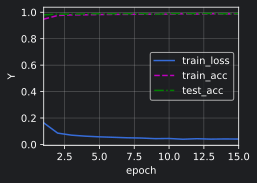

In [4]:
import os
os.environ["TORCH_HOME"] = "D:/CodeProject/TorchCache"
# Data Loading
batch_size = 32
data_dir = "../../data/CatDogs/cartoonvsnormal"

root = os.path.join(data_dir, "train")
print("root:", os.path.abspath(root))
print("存在:", os.path.isdir(root))

import inspect
print(inspect.getsource(get_mean_std))

count = 0
for dirpath, _, files in os.walk(root):
    count += len(files)
print("遍历到的文件总数:", count)

from torchvision import datasets, transforms
root = r"D:\CodeProject\Python\d2l_study\data\CatDogs\cartoonvsnormal\train"
ds = datasets.ImageFolder(root, transform=transforms.ToTensor())
print("ImageFolder 样本数:", len(ds), "| 类别:", ds.class_to_idx)


mean_train_list, std_train_list = get_mean_std(os.path.join(data_dir, "train"), 'train')
cartoon_num = len(os.listdir(os.path.join(data_dir, 'train','cartoon')))
normal_num = len(os.listdir(os.path.join(data_dir, 'train','normal')))
train_iter, image_train_datasets = load_data_cartoon_vs_normal(os.path.join(data_dir, 'train'), mean_train_list, std_train_list, batch_size)
test_iter, image_test_datasets = load_data_cartoon_vs_normal(os.path.join(data_dir, 'test'), mean_train_list, std_train_list, batch_size)
index_classes = list(image_test_datasets.class_to_idx.keys())
print("Class one {}，Number {}，Class two {} Number {}".format(index_classes[0], cartoon_num,index_classes[1], normal_num))

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
use_gpu = torch.cuda.is_available()

for param in model.parameters():
    param.requires_grad = False
model.fc = torch.nn.Linear(2048,2)
nn.init.xavier_uniform_(model.fc.weight)
nn.init.zeros_(model.fc.bias)

if use_gpu:
    model = model.cuda()

idx = image_train_datasets.class_to_idx
num_per_class = {
    idx['cartoon']: len(os.listdir(os.path.join(data_dir, 'train', 'cartoon'))),
    idx['normal']:  len(os.listdir(os.path.join(data_dir, 'train', 'normal'))),
}
total = sum(num_per_class.values())

# Loss Function and Optimizer
weight = torch.tensor(
    [total / num_per_class[i] for i in range(len(idx))], dtype=torch.float32)
weight = weight.cuda() if use_gpu else weight


loss_f = torch.nn.CrossEntropyLoss(weight=weight)
optimizer = torch.optim.SGD(model.fc.parameters(), lr=1e-3, momentum=0.9)

num_epochs = 15
save_dir = "../../data/CatDogs"
os.makedirs(save_dir, exist_ok=True)
train_ch4_9(model, train_iter, test_iter, loss_f, num_epochs, optimizer, use_gpu,
            save_name=os.path.join(save_dir, "cartoon_vs_normal_resnet50.pth"))

del model
torch.cuda.empty_cache()

In [2]:
def covariate_shift_detector(
        input_image,
        model_pth='../../data/CatDogs/covariate_shift_detectormodel.pth'):
    softmax=nn.Softmax(dim=1)
    use_gpu = torch.cuda.is_available()
    device = torch.device('cuda' if use_gpu else 'cpu')
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    model.fc = torch.nn.Linear(2048,2)
    state = torch.load(Path(model_pth).expanduser(), map_location=device, weights_only=True)
    model.load_state_dict(state)
    model.to(device).eval()

    if input_image.dim() == 3:
        input_image = input_image.unsqueeze(0)
    input_image = input_image.to(device)

    with torch.no_grad():
        probs  = softmax(model(input_image))
        betas  = (probs[:, 0] / (probs[:, 1] + 1e-8)).clamp(max=1.0)

    if betas.numel() == 1:
        return float(betas.item())
    return betas

In [12]:
import random
#test_iter,image_test_datasets=load_data_cartoonvsnormal(os.path.join(data_dir, 'test'),batch_size)
test_num = random.randint(0,len(image_test_datasets)-1)
index_classes = list(image_test_datasets.class_to_idx.keys())
input_image = torch.unsqueeze(image_test_datasets[test_num][0],0)
if torch.cuda.is_available():
    input_image = input_image.cuda()
output = index_classes[0] if covariate_shift_detector(input_image)>=1 else index_classes[1]
print("test num ",test_num," interfere category：",output, " actual category：",index_classes[image_test_datasets[test_num][1]])
del input_image


testnum  563  推断类别： cartoon 实际类别： cartoon


In [15]:
import gc
import torch
import torch.nn as nn
from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader

use_gpu = torch.cuda.is_available()
device  = torch.device('cuda' if use_gpu else 'cpu')
model_pth='../../data/CatDogs/covariate_shift_detectormodel.pth'

# --- 1. 构建 detector（只一次）---
detector = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
detector.fc = nn.Linear(2048, 2)
state = torch.load(Path(model_pth).expanduser(), map_location=device, weights_only=True)
detector.load_state_dict(state)
detector.to(device).eval()
softmax = nn.Softmax(dim=1)

# --- 2. 分批推理 ---
infer_loader = DataLoader(image_test_datasets, batch_size=64, shuffle=False, num_workers=0)

betas_list = []
with torch.no_grad():
    for X, _ in infer_loader:
        X    = X.to(device)
        prob = softmax(detector(X))
        b    = (prob[:, 0] / (prob[:, 1] + 1e-8)).clamp(max=1.0)
        betas_list.append(b.cpu())

output = torch.cat(betas_list)          # [N]，CPU

# --- 3. 算准确率（向量化，不用 map/lambda）---
test_label = torch.tensor([i[1] for i in image_test_datasets])   # [N]，CPU
pred       = (output < 1).long()
correct    = (pred == test_label)

cartoon_mask = (test_label == 0)
normal_mask  = (test_label == 1)

cartoon_acc = correct[cartoon_mask].float().mean().item() if cartoon_mask.any() else float('nan')
normal_acc  = correct[normal_mask].float().mean().item()  if normal_mask.any()  else float('nan')

print(f"Accuracy of cartoon image predictions: {100*cartoon_acc:.2f}% , "
      f"Accuracy of normal image predictions: {100*normal_acc:.2f}%")

# --- 4. 清理 ---
del detector, infer_loader, betas_list
gc.collect()
if use_gpu:
    torch.cuda.empty_cache()

Accuracy of cartoon image predictions: 6.00% , Accuracy of normal image predictions: 4.32%


# **Question 4.9.3**
**3.Implement covariate offset correction.**

epoch3 Loss:0.2793 Train Acc:92.7900% Test Cartoon Acc:83.1200% Test Normal Acc:94.3400%
Batch:200,Train Loss:0.2480,Train ACC:93.8125%


KeyboardInterrupt: 

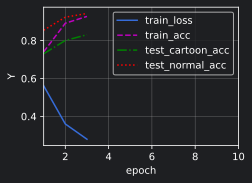

In [5]:
# Data Loading
import os
os.environ["TORCH_HOME"] = "D:/CodeProject/TorchCache"
batch_size=32
data_dir = "../../data/CatDogs/dogvscat"
mean_train_list,std_train_list = get_mean_std(os.path.join(data_dir, 'train'),'train')
mean_testcartoon_list,std_testcartoon_list = get_mean_std(os.path.join(data_dir, 'testcartoon'),'testcartoon')
mean_testnormal_list,std_testnormal_list = get_mean_std(os.path.join(data_dir, 'test'),'testnormal')
train_iter,image_train_datasets = load_data_cartoon_vs_normal(os.path.join(data_dir, 'train'),mean_train_list,std_train_list,batch_size)
testcartoon_iter,image_testcartoon_datasets = load_data_cartoon_vs_normal(os.path.join(data_dir, 'testcartoon'),mean_testcartoon_list,std_testcartoon_list,batch_size)
testnormal_iter,image_testnormal_datasets = load_data_cartoon_vs_normal(os.path.join(data_dir, 'test'),mean_testnormal_list,std_testnormal_list,batch_size)

#model loading
model_no_detector = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
use_gpu = torch.cuda.is_available()

for parma in model_no_detector.parameters():
    parma.requires_grad = False
model_no_detector.fc = torch.nn.Linear(2048,2)
nn.init.xavier_uniform_(model_no_detector.fc.weight);


if use_gpu:
    model_no_detector = model_no_detector.cuda()

# loss function and optimizer
loss_f = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_no_detector.fc.parameters(),lr =  1e-4)

num_epochs = 10
train_ch4_9(model_no_detector, train_iter, testcartoon_iter, loss_f, num_epochs,optimizer,use_gpu, test_iter2=testnormal_iter, save_name='../../data/CatDogs/dogvscatwithoutdetectormodel.pth')
#清除内存
del model_no_detector
torch.cuda.empty_cache()


In [ ]:
gc.collect()# memory cleaning
import os
os.environ["TORCH_HOME"] = "D:/CodeProject/TorchCache"
# data loading
batch_size=32
data_dir = "../../data/CatDogs/dogvscat"
mean_train_list,std_train_list=get_mean_std(os.path.join(data_dir, 'train'),'train')
mean_testcartoon_list,std_testcartoon_list=get_mean_std(os.path.join(data_dir, 'testcartoon'),'testcartoon')
mean_testnormal_list,std_testnormal_list=get_mean_std(os.path.join(data_dir, 'test'),'testnormal')
train_iter,image_train_datasets=load_data_cartoon_vs_normal(os.path.join(data_dir, 'train'),mean_train_list,std_train_list,batch_size)
testcartoon_iter,image_testcartoon_datasets=load_data_cartoon_vs_normal(os.path.join(data_dir, 'testcartoon'),mean_testcartoon_list,std_testcartoon_list,batch_size)
testnormal_iter,image_testnormal_datasets=load_data_cartoon_vs_normal(os.path.join(data_dir, 'test'),mean_testnormal_list,std_testnormal_list,batch_size)
#加载模型
model_detector = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
use_gpu = torch.cuda.is_available()
if use_gpu:
    #del modelwithoutdetector
    torch.cuda.empty_cache()
    print('clear')
for parma in model_detector.parameters():
    parma.requires_grad = False
model_detector.fc = torch.nn.Linear(2048,2)
nn.init.xavier_uniform_(model_detector.fc.weight);


if use_gpu:
    model_detector = model_detector.cuda()

#损失函数和优化器
def myloss(y_hat,y,beta):
    loss_f = torch.nn.CrossEntropyLoss(reduction='none')
    l=loss_f(y_hat,y)
    return torch.mul(beta,l).mean()


optimizer = torch.optim.SGD(model_detector.fc.parameters(),lr =1e-4)

num_epochs = 10
train_ch4_9(model_detector, train_iter, testcartoon_iter,myloss, num_epochs,optimizer,use_gpu,test_iter2=testnormal_iter,save_name='../../data/CatDogs/dogvscatwithdetectormodel.pth',detector=covariate_shift_detector)
#清除内存
del model_detector
torch.cuda.empty_cache()


In [ ]:
gc.collect() # memory cleaning
import os
os.environ["TORCH_HOME"] = "D:/CodeProject/TorchCache"
# data loading
batch_size=32
data_dir = "../../data/CatDogs/dogvscat"
mean_train_list,std_train_list=get_mean_std(os.path.join(data_dir, 'train'),'train')
mean_testcartoon_list,std_testcartoon_list=get_mean_std(os.path.join(data_dir, 'testcartoon'),'testcartoon')
mean_testnormal_list,std_testnormal_list=get_mean_std(os.path.join(data_dir, 'test'),'testnormal')
train_iter,image_train_datasets=load_data_cartoon_vs_normal(os.path.join(data_dir, 'train'),mean_train_list,std_train_list,batch_size)
testcartoon_iter,image_testcartoon_datasets=load_data_cartoon_vs_normal(os.path.join(data_dir, 'testcartoon'),mean_testcartoon_list,std_testcartoon_list,batch_size)
testnormal_iter,image_testnormal_datasets=load_data_cartoon_vs_normal(os.path.join(data_dir, 'test'),mean_testnormal_list,std_testnormal_list,batch_size)
#加载模型
model_detector = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
Use_gpu = torch.cuda.is_available()
if Use_gpu:
    #del modelwithoutdetector
    torch.cuda.empty_cache()
    print('clear')
for parma in model_detector.parameters():
    parma.requires_grad = False#屏蔽预训练模型的权重，只训练最后一层的全连接的权重
model_detector.fc = torch.nn.Linear(2048,2)
nn.init.xavier_uniform_(model_detector.fc.weight);  # 对神经网络模型参数进行Xavier均匀分布初始化


if Use_gpu:
    model_detector = model_detector.cuda()

#损失函数和优化器
def myloss(y_hat,y,beta):
    loss_f = torch.nn.CrossEntropyLoss(reduction='none')
    l=loss_f(y_hat,y)
    return 25*torch.mul(beta,l).mean() #直接使用beta计算结果 并没有改善 这可能是因为beta小于1 使loss变小 导致更新梯度以后 变化不大 所以乘以一个数 以改善这种情况


optimizer = torch.optim.SGD(model_detector.fc.parameters(),lr =1e-4)

num_epochs = 10
train_ch4_9(model_detector, train_iter, testcartoon_iter,myloss, num_epochs,optimizer,Use_gpu,test_iter2=testnormal_iter,save_name='../../data/CatDogs/dogvscatwithdetectormodel.pth',detector=covariate_shift_detector)
#清除内存
del model_detector
torch.cuda.empty_cache()


In [ ]:
gc.collect()
import os
os.environ["TORCH_HOME"] = "D:/CodeProject/TorchCache"
use_gpu = torch.cuda.is_available()
if use_gpu:
    #del modelwithoutdetector
    torch.cuda.empty_cache()
    print('clear')
data_dir = "../../data/CatDogs/dogvscat"
batch_size=32
mean_testcartoon_list,std_testcartoon_list=get_mean_std(os.path.join(data_dir, 'testcartoon'),'testcartoon')
testcartoon_iter,image_testcartoon_datasets=load_data_cartoon_vs_normal(os.path.join(data_dir, 'testcartoon'), mean_testcartoon_list,std_testcartoon_list,batch_size)
#加载模型
model_detector = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
model_detector.fc = torch.nn.Linear(2048,2)
model_detector.load_state_dict(torch.load('../../data/CatDogs/dogvscatwithdetectormodel.pth'))
#加载模型\
model_no_detector = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
model_no_detector.fc = torch.nn.Linear(2048,2)
model_no_detector.load_state_dict(torch.load('../../data/CatDogs/dogvscatwithoutdetectormodel.pth'))
print("Accuracy without classification: {:.4f}%, Accuracy without classification: {:.4f}%".format(100*evaluate_accuracy_ch4_9(model_no_detector,testcartoon_iter,Use_gpu),100*evaluate_accuracy_ch4_9(model_detector, testcartoon_iter,Use_gpu)))
#清除内存
del model_no_detector
del model_detector
torch.cuda.empty_cache()


# **Question 4.9.4**
**4.Apart from distribution shifts, what else affects the degree to which empirical risk approximates true risk?**<br><br>
In addition to distribution shifts, the following factors may also affect the extent to which empirical risk approximates true risk:<br>
1. Sample Size: The accuracy of empirical risk estimates generally increases as the sample size increases. A larger sample size provides more information, making the risk estimates more reliable.
2. Feature Selection: Selecting appropriate features can reduce the impact of noise and redundant information, thereby improving estimates of true risk. Effective feature selection helps improve a model’s generalization ability.
3. Model Complexity: A model’s complexity is closely related to its performance on the training data and its estimation of true risk. A model that is too simple may fail to capture the complex relationships in the data, while a model that is too complex may overfit the training data, leading to a wider gap between empirical risk and true risk.
4. Data Quality: Data quality is critical to the accuracy of experience-based risk assessments. Low-quality data, or data containing errors or missing values, can lead to incorrect model training and risk estimates.
5. Sample selection bias: If the sample is selected inappropriately or is biased—for example, if the sampling method is not random or the sample is not representative of the population—then the empirical risk may not accurately estimate the true risk.
6. Noise and Outliers: Noise and outliers in the data can interfere with estimates of empirical risk. These outliers may cause the model to overfit, leading to inaccurate estimates of the true risk.